In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

results_folder = Path("data/processed")

comparison = pd.read_csv(
    results_folder / "model_comparison.csv",
    index_col="model"
)

test_metrics = pd.read_csv(
    results_folder / "final_test_metrics.csv",
    index_col="metric"
)

predictions = pd.read_csv(
    results_folder / "test_predictions.csv"
)

comparison.round(3)

,Accuracy,Recall,ROC-AUC
model,,,
Baseline,0.541,0.000,0.500
Logistic Regression,0.847,0.784,0.906
Decision Tree,0.773,0.729,0.832
Random Forest,0.814,0.774,0.900
KNN,0.826,0.792,0.873


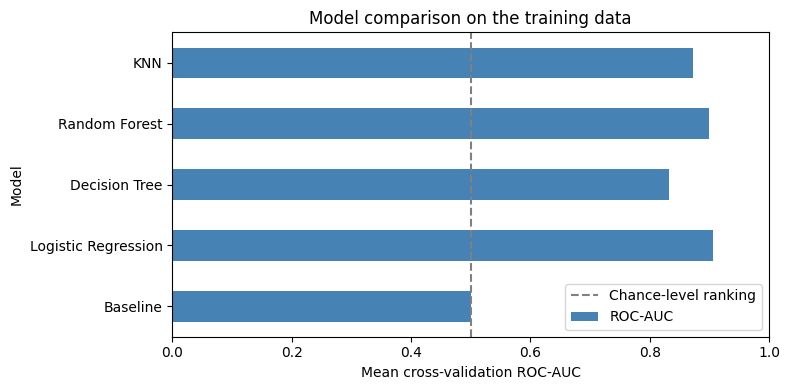

In [8]:
comparison["ROC-AUC"].plot(
    kind="barh",
    figsize=(8, 4),
    color="steelblue"
)

plt.xlabel("Mean cross-validation ROC-AUC")
plt.ylabel("Model")
plt.title("Model comparison on the training data")
plt.xlim(0, 1)
plt.axvline(0.5, color="grey", linestyle="--", label="Chance-level ranking")
plt.legend()
plt.tight_layout()
plt.show()

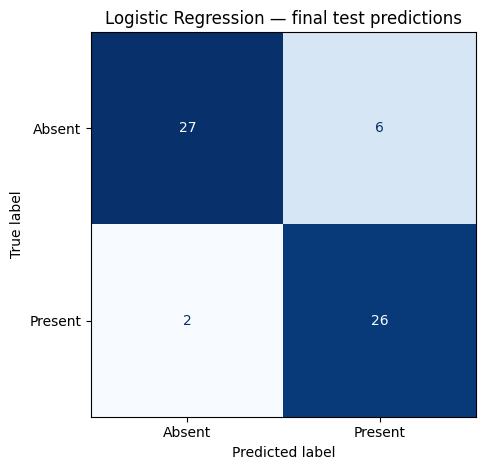

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    predictions["actual"],
    predictions["predicted"],
    labels=[0, 1],
    display_labels=["Absent", "Present"],
    cmap="Blues",
    colorbar=False
)

plt.title("Logistic Regression — final test predictions")
plt.tight_layout()
plt.show()

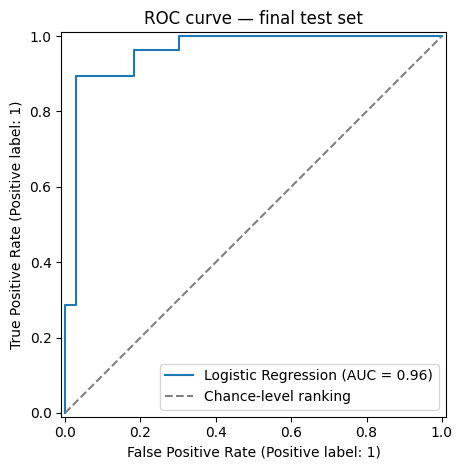

In [10]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    predictions["actual"],
    predictions["probability"],
    name="Logistic Regression"
)

plt.plot([0, 1], [0, 1], "--", color="grey", label="Chance-level ranking")
plt.title("ROC curve — final test set")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
from sklearn.metrics import roc_curve

false_positive_rate, true_positive_rate, thresholds = roc_curve(
    predictions["actual"],
    predictions["probability"]
)

roc_data = pd.DataFrame({
    "false_positive_rate": false_positive_rate,
    "true_positive_rate": true_positive_rate
})

roc_data.to_csv(results_folder / "roc_curve.csv", index=False)

print("ROC curve data exported.")

ROC curve data exported.


In [12]:
from sklearn.metrics import confusion_matrix

matrix = confusion_matrix(
    predictions["actual"],
    predictions["predicted"],
    labels=[0, 1]
)

confusion_data = pd.DataFrame({
    "actual_status": ["Absent", "Absent", "Present", "Present"],
    "predicted_status": ["Absent", "Present", "Absent", "Present"],
    "count": matrix.ravel()
})

confusion_data.to_csv(
    results_folder / "confusion_matrix.csv",
    index=False
)

confusion_data

,actual_status,predicted_status,count
0,Absent,Absent,27
1,Absent,Present,6
2,Present,Absent,2
3,Present,Present,26


## Results and interpretation

Logistic Regression achieved the highest mean cross-validation
accuracy (84.7%) and ROC-AUC (0.906) among the models compared.

On the 61-record test set, it achieved:
- Accuracy: 86.9%
- Precision: 81.2%
- Recall: 92.9%
- ROC-AUC: 0.958

It correctly classified 53 records, with six false positives
and two false negatives.

## Limitations

- The dataset is small and historical.
- Results from one test split may vary with a different sample.
- Exploratory analysis examined the full dataset before modelling,
  so the test set is not a completely independent confirmation.
- The sample does not establish general-population disease prevalence.
- Associations do not establish causation.
- Probability calibration and external validation were not assessed.
- This is an educational classification project, not a clinical tool.

## Reproducing the results

Run Notebook 02 before this notebook to generate the input CSV files.
The exported tables support the Tableau dashboard.